## Import liberaries

In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

## Data Pipline

In [5]:



class datapipline:
    def __init__(self, file_path):
        self.file_path = str(file_path).strip().strip('"').strip("'")
        self.df = None
        self._load_data()

    def _load_data(self):
        try:
            if self.file_path.endswith('.csv'):
                self.df = pd.read_csv(self.file_path)
                
            elif self.file_path.endswith(('.xls', '.xlsx')):
                self.df = pd.read_excel(self.file_path)
               
            else:
                raise ValueError("Your file format is not supported. Please provide a CSV or Excel file.")
                
        except FileNotFoundError:
            print(f" your path is not found: {self.file_path}")
        

    
    def clean(self):
        if self.df is None: return self
            
        
        if 'Row ID' in self.df.columns:
            self.df = self.df.drop(columns=['Row ID'])

        
        self.df['Order Date'] = pd.to_datetime(self.df['Order Date'], errors='coerce')
        self.df['Ship Date'] = pd.to_datetime(self.df['Ship Date'], errors='coerce')
        
        if 'Postal Code' in self.df.columns:
            self.df['Postal Code'] = self.df['Postal Code'].astype(str)

        
        self.df['shipping_days'] = (self.df['Ship Date'] - self.df['Order Date']).dt.days

        
        if 'Profit' in self.df.columns and 'Sales' in self.df.columns:
            self.df['profit_margin'] = (self.df['Profit'] / self.df['Sales']).round(2)

        
        return self


    def plot_correlation(self):
        if self.df is None: return self
        plt.figure(figsize=(6, 4))
        corr = self.df[['Sales', 'Profit']].corr()
        sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=1)
        plt.title('Correlation Heatmap: Sales vs Profit')
        plt.tight_layout()
        plt.show()
        return self

    
    def plot_sales_breakdown(self):
        if self.df is None: return self
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        
        
        sales_cat = self.df.groupby('Category')['Sales'].sum().reset_index()
        sns.barplot(data=sales_cat, x='Category', y='Sales', ax=axes[0], palette='Blues_d')
        axes[0].set_title('Total Sales by Category')
        
        
        sales_sub = self.df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).reset_index()
        sns.barplot(data=sales_sub, x='Sales', y='Sub-Category', ax=axes[1], palette='Blues_r')
        axes[1].set_title('Total Sales by Sub-Category')
        
        plt.tight_layout()
        plt.show()
        return self

   
    def plot_shipping_pie(self):
        if self.df is None: return self
        avg_ship = self.df.groupby('Ship Mode')['shipping_days'].mean()
        
        plt.figure(figsize=(7, 7))
        plt.pie(avg_ship, labels=avg_ship.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set2'))
        plt.title('Avg Shipping Days Share by Ship Mode')
        plt.show()
        return self

    
    def plot_shipping_by_state(self):
        if self.df is None:
          return self

        standard_df = self.df[self.df['Ship Mode'] == 'Standard Class']

        avg_state = (
        standard_df
        .groupby('State')['shipping_days']
        .mean()
        .sort_values(ascending=False)
        .head(3)
        .reset_index())
     
        plt.figure(figsize=(12, 5))
        sns.barplot(
        data=avg_state,
        x='State',
        y='shipping_days',
        palette='magma')
    

        plt.xticks(rotation=45)
        plt.title('Top 3 States by Avg Shipping Days - Standard Class')
        plt.tight_layout()
        plt.show()
        return self
     

    
    def plot_segment_counts(self):
        if self.df is None: return self
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        
        
        sns.countplot(data=self.df, x='Segment', hue='Category', ax=axes[0], palette='Set1')
        axes[0].set_title('Count of Categories per Segment')
        
        
        sns.countplot(data=self.df, x='Segment', hue='Sub-Category', ax=axes[1], palette='tab20')
        axes[1].set_title('Count of Sub-Categories per Segment')
        axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        
        plt.tight_layout()
        plt.show()
        return self

    
    def plot_profit_margin_by_subcat(self):
        if self.df is None: return self
        margin_sub = self.df.groupby('Sub-Category')['profit_margin'].mean().sort_values(ascending=False).reset_index()
        
        plt.figure(figsize=(12, 5))
        sns.barplot(data=margin_sub, x='Sub-Category', y='profit_margin', palette='Greens_r')
        plt.xticks(rotation=45)
        plt.title('Average Profit Margin by Sub-Category')
        plt.tight_layout()
        plt.show()
        return self

    def get_data(self):
        return self.df


## EDA

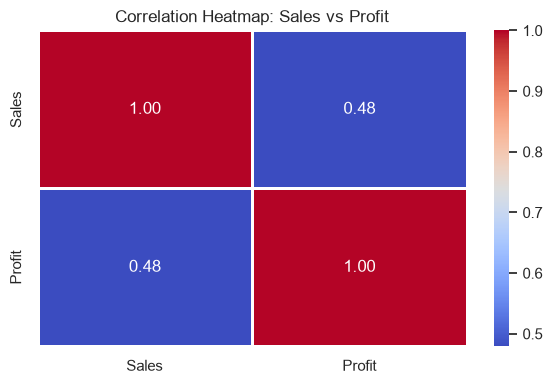

C:\Users\mmaf\AppData\Local\Temp\ipykernel_10496\1010735578.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_cat, x='Category', y='Sales', ax=axes[0], palette='Blues_d')
C:\Users\mmaf\AppData\Local\Temp\ipykernel_10496\1010735578.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_sub, x='Sales', y='Sub-Category', ax=axes[1], palette='Blues_r')


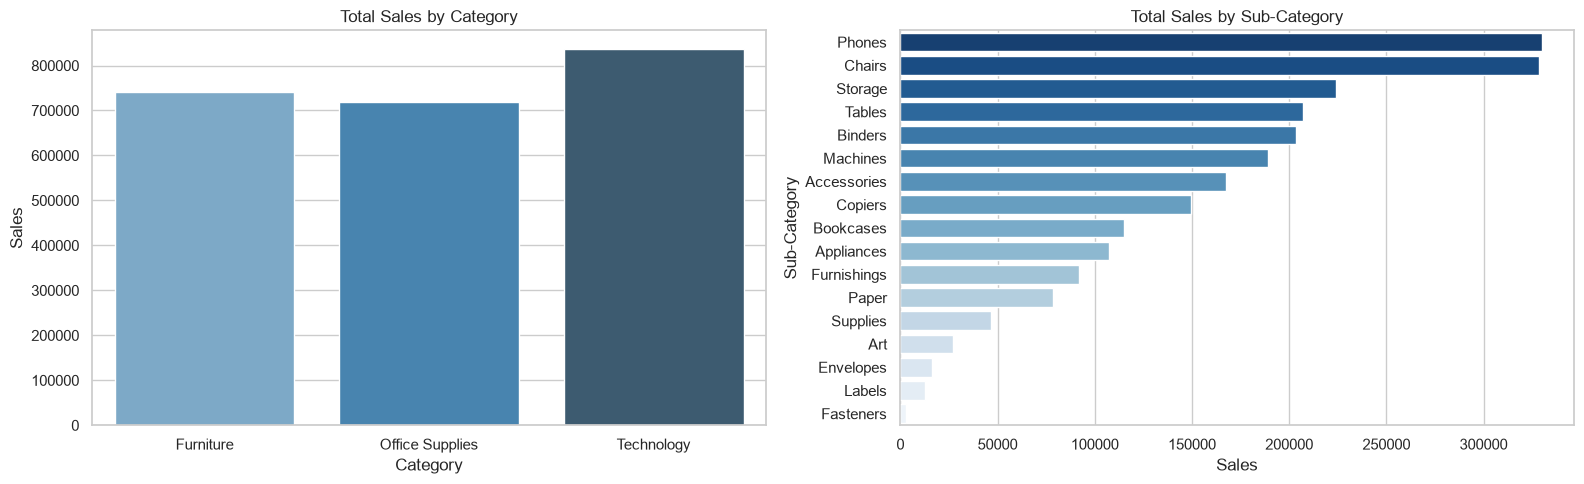

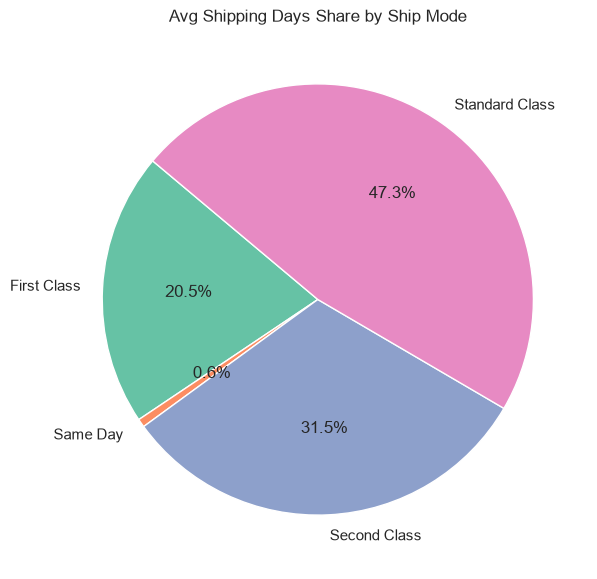

C:\Users\mmaf\AppData\Local\Temp\ipykernel_10496\1010735578.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


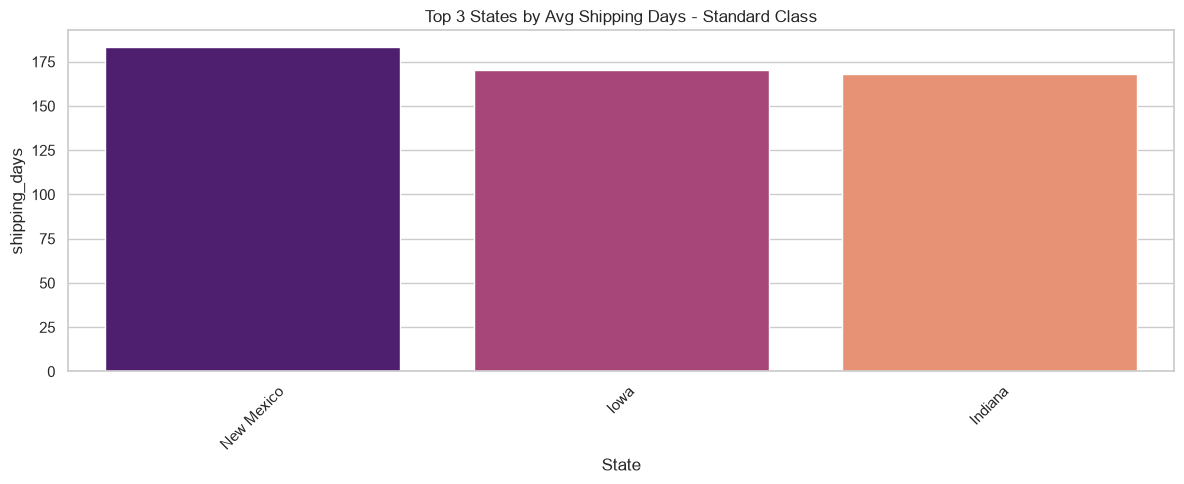

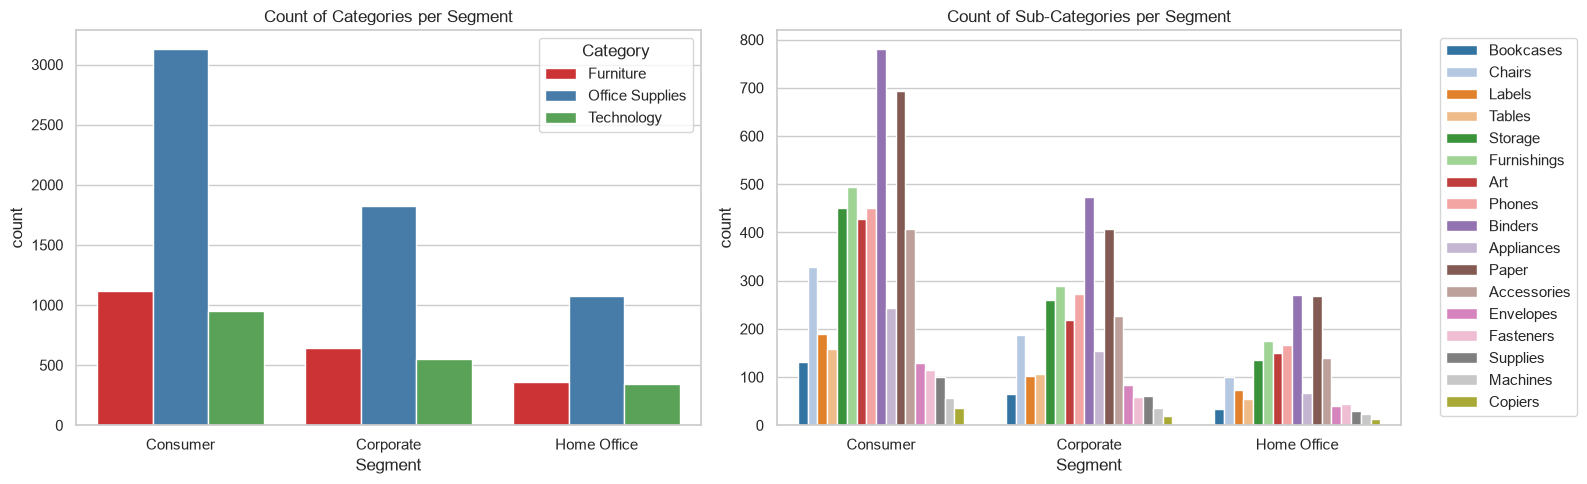

C:\Users\mmaf\AppData\Local\Temp\ipykernel_10496\1010735578.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=margin_sub, x='Sub-Category', y='profit_margin', palette='Greens_r')


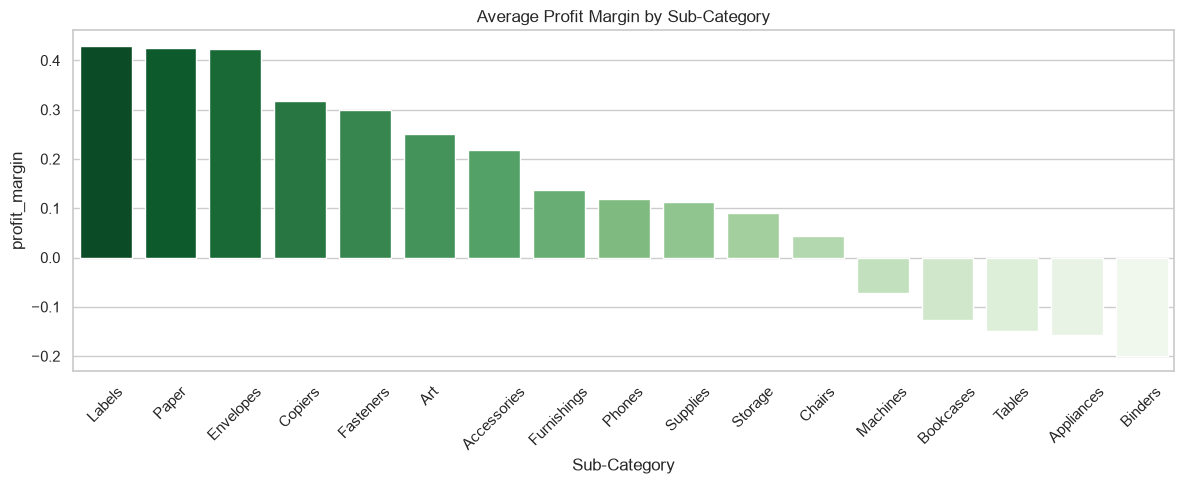

In [6]:
cc=( datapipline('Sample - Superstore 2019.csv').clean()
    .plot_correlation()
    .plot_sales_breakdown()
    .plot_shipping_pie()
    .plot_shipping_by_state()
    .plot_segment_counts()
    .plot_profit_margin_by_subcat()
    .get_data()
    )